In [1]:
import requests
url = "https://en.wikipedia.org/wiki/Cat"
response = requests.get(url)
cat_text = response.text
# Extract text from HTML
from bs4 import BeautifulSoup
soup = BeautifulSoup(cat_text, 'html.parser')
cat_text = soup.get_text()

In [2]:
from collections import Counter
letter_counts = Counter(c.lower() for c in cat_text if c.isalpha())
# Sort by frequency
sorted_letter_counts = sorted(letter_counts.items(), key=lambda x: x[1], reverse=True)

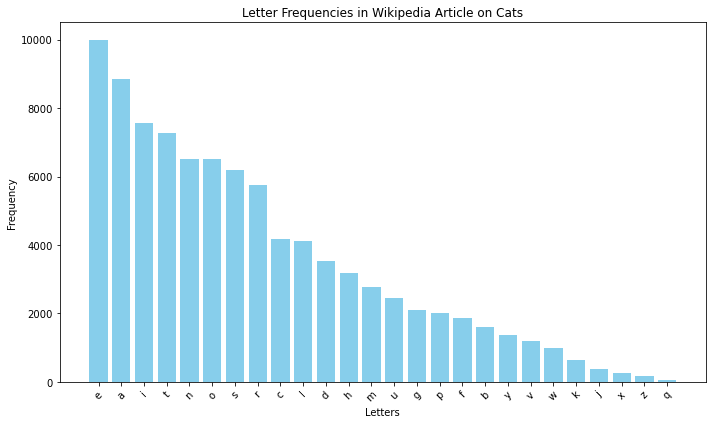

In [3]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
sorted_letter_counts = sorted_letter_counts[:26]  # Limit to top 26 letters
letters, counts = zip(*sorted_letter_counts)
plt.bar(letters, counts, color='skyblue')
plt.xlabel('Letters')
plt.ylabel('Frequency')
plt.title('Letter Frequencies in Wikipedia Article on Cats')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [4]:
import numpy as np
# Generate text one letter at a time by sampling from the letter frequencies
counts = np.array(counts)/sum(counts)  # Normalize counts to probabilities
import random
gentext = random.choices(letters, weights=counts, k=20)
print("Generated letters:", ''.join(gentext))

Generated letters: ppcrearvanlimeaorlhs


In [5]:
# NLTK 2-gram Text Generation from War and Peace
import nltk
from nltk.tokenize import word_tokenize
from nltk.util import bigrams
from collections import defaultdict, Counter
import random
import re

# Download required NLTK data
nltk.download('punkt', quiet=True)

# Read the War and Peace text file
with open('data/warpeace.txt', 'r', encoding='utf-8') as file:
    warpeace_text = file.read()

print(f"Text length: {len(warpeace_text)} characters")
print(f"First 200 characters: {warpeace_text[:200]}")

Text length: 3196213 characters
First 200 characters: ﻿"Well, Prince, so Genoa and Lucca are now just family estates of the
Buonapartes. But I warn you, if you don't tell me that this means war,
if you still try to defend the infamies and horrors perpetr


In [6]:
# Preprocess the text: clean and tokenize
# Remove chapter headers and clean text
text_lines = warpeace_text.split('\n')
clean_lines = []
for line in text_lines:
    # Skip empty lines and chapter headers
    line = line.strip()
    if line and not line.startswith('CHAPTER') and not line.isupper():
        clean_lines.append(line)

clean_text = ' '.join(clean_lines)

# Convert to lowercase and remove non-alphabetic characters except spaces and basic punctuation
clean_text = re.sub(r'[^a-zA-Z\s.,!?;:]', '', clean_text.lower())

# Download additional required NLTK data
nltk.download('punkt_tab', quiet=True)

# Tokenize into words
tokens = word_tokenize(clean_text)
print(f"Number of tokens: {len(tokens)}")
print(f"First 20 tokens: {tokens[:20]}")

# Build 2-gram model
bigram_model = defaultdict(Counter)

# Create bigrams and build frequency model
for w1, w2 in bigrams(tokens):
    bigram_model[w1][w2] += 1

print(f"\nNumber of unique first words in bigrams: {len(bigram_model)}")
print(f"Sample bigrams for 'the': {dict(bigram_model['the'].most_common(10))}")
print(f"Sample bigrams for 'war': {dict(bigram_model['war'].most_common(10))}")
print(f"Sample bigrams for 'peace': {dict(bigram_model['peace'].most_common(10))}")

Number of tokens: 636771
First 20 tokens: ['well', ',', 'prince', ',', 'so', 'genoa', 'and', 'lucca', 'are', 'now', 'just', 'family', 'estates', 'of', 'the', 'buonapartes', '.', 'but', 'i', 'warn']

Number of unique first words in bigrams: 19987
Sample bigrams for 'the': {'same': 614, 'french': 584, 'emperor': 476, 'old': 428, 'first': 367, 'whole': 331, 'room': 312, 'countess': 312, 'count': 299, 'other': 290}
Sample bigrams for 'war': {',': 58, '.': 37, 'and': 22, 'was': 18, 'with': 13, 'is': 12, '!': 7, 'began': 6, 'of': 6, 'had': 5}
Sample bigrams for 'peace': {'.': 21, ',': 20, 'and': 14, 'of': 7, 'with': 7, 'in': 3, '!': 3, 'is': 2, 'concluded': 2, 'were': 2}

Number of unique first words in bigrams: 19987
Sample bigrams for 'the': {'same': 614, 'french': 584, 'emperor': 476, 'old': 428, 'first': 367, 'whole': 331, 'room': 312, 'countess': 312, 'count': 299, 'other': 290}
Sample bigrams for 'war': {',': 58, '.': 37, 'and': 22, 'was': 18, 'with': 13, 'is': 12, '!': 7, 'began': 6, 

In [7]:
# Text generation function using the 2-gram model
def generate_text(model, start_word=None, max_length=200):
    """
    Generate text using the 2-gram model.
    
    Args:
        model: Dictionary of bigram frequencies
        start_word: Word to start with (if None, pick randomly)
        max_length: Maximum number of characters to generate
    
    Returns:
        Generated text string
    """
    if start_word is None or start_word not in model:
        # Start with a random word that has following words
        start_word = random.choice(list(model.keys()))
    
    words = [start_word]
    current_word = start_word
    generated_text = start_word
    
    while len(generated_text) < max_length:
        # Get possible next words for current word
        if current_word in model and model[current_word]:
            # Get words and their frequencies
            possible_words = list(model[current_word].keys())
            frequencies = list(model[current_word].values())
            
            # Normalize frequencies to probabilities
            total_freq = sum(frequencies)
            probabilities = [f/total_freq for f in frequencies]
            
            # Choose next word based on probabilities
            next_word = random.choices(possible_words, weights=probabilities)[0]
            
            # Add word to generated text
            if next_word in '.,!?;:':
                generated_text += next_word
            else:
                generated_text += ' ' + next_word
            
            current_word = next_word
            words.append(next_word)
            
            # Stop at sentence endings occasionally
            if next_word in '.!?' and random.random() < 0.3:
                break
        else:
            # If current word has no followers, pick a new random word
            current_word = random.choice(list(model.keys()))
            generated_text += ' ' + current_word
            words.append(current_word)
    
    return generated_text

# Generate several text samples
print("Generated text samples using 2-gram model from War and Peace:\n")

# Generate 5 different samples
for i in range(5):
    start_words = ['the', 'war', 'peace', 'napoleon', 'prince']
    start_word = start_words[i % len(start_words)]
    
    generated = generate_text(bigram_model, start_word, max_length=200)
    print(f"Sample {i+1} (starting with '{start_word}'):")
    print(generated)
    print("\n" + "-"*80 + "\n")

# Generate one longer sample (target 200 characters)
print("\nFinal 200-character sample:")
final_text = generate_text(bigram_model, start_word='the', max_length=200)
print(f"Length: {len(final_text)} characters")
print(final_text)

Generated text samples using 2-gram model from War and Peace:

Sample 1 (starting with 'the'):
the shirt straight before a ball in the pillow, as the first of the demand of his room. in his estates in french army, who was pierre lacked the news had been jealous of the studythat was perfect, came

--------------------------------------------------------------------------------

Sample 2 (starting with 'war'):
war with even more especially about her own happiness was there are you do it with the air of a long time nesvitski was pierres journeys and then guessed her. your hands. that wine which we have some precious

--------------------------------------------------------------------------------

Sample 3 (starting with 'peace'):
peace! he heard, began to an appearance of his hearer, or an illegitimate son coldly. what he was a shrewd and time everywhere and run it had seen behind the whole property of events where nothing terrible

-------------------------------------------------------

In [8]:
# CHARACTER-BASED N-GRAM MODELS (n=2,3,4,5)
print("="*80)
print("CHARACTER-BASED N-GRAM TEXT GENERATION")
print("="*80)

# Prepare character data from War and Peace text
print("Preparing character data...")

# Use the cleaned text but preserve more characters for realistic generation
char_text = re.sub(r'[^\w\s.,!?;:\'-]', '', warpeace_text.lower())
# Remove extra whitespace
char_text = re.sub(r'\s+', ' ', char_text)

print(f"Character data length: {len(char_text):,} characters")
print(f"Unique characters: {len(set(char_text))}")
print(f"Sample: '{char_text[:100]}...'")

# Build character n-gram models
char_ngram_models = {}

for n in [2, 3, 4, 5]:
    print(f"\nBuilding {n}-gram character model...")
    char_model = defaultdict(Counter)
    
    # Create character n-grams
    for i in range(len(char_text) - n + 1):
        context = char_text[i:i+n-1]  # n-1 characters as context
        next_char = char_text[i+n-1]  # next character
        char_model[context][next_char] += 1
    
    char_ngram_models[n] = char_model
    
    # Statistics
    contexts = len(char_model)
    total_transitions = sum(len(transitions) for transitions in char_model.values())
    avg_transitions = total_transitions / contexts if contexts > 0 else 0
    
    print(f"  - Contexts: {contexts:,}")
    print(f"  - Total transitions: {total_transitions:,}")
    print(f"  - Avg transitions per context: {avg_transitions:.1f}")

print("\nCharacter n-gram models built successfully!")

CHARACTER-BASED N-GRAM TEXT GENERATION
Preparing character data...
Character data length: 3,164,835 characters
Unique characters: 49
Sample: 'well, prince, so genoa and lucca are now just family estates of the buonapartes. but i warn you, if ...'

Building 2-gram character model...
  - Contexts: 49
  - Total transitions: 969
  - Avg transitions per context: 19.8

Building 3-gram character model...
  - Contexts: 49
  - Total transitions: 969
  - Avg transitions per context: 19.8

Building 3-gram character model...
  - Contexts: 969
  - Total transitions: 9,070
  - Avg transitions per context: 9.4

Building 4-gram character model...
  - Contexts: 969
  - Total transitions: 9,070
  - Avg transitions per context: 9.4

Building 4-gram character model...
  - Contexts: 9,070
  - Total transitions: 42,542
  - Avg transitions per context: 4.7

Building 5-gram character model...
  - Contexts: 9,070
  - Total transitions: 42,542
  - Avg transitions per context: 4.7

Building 5-gram character mode

In [9]:
# Character-based text generation functions
def generate_char_text(model, n, start_context=None, max_length=200):
    """
    Generate text using character-based n-gram model.
    
    Args:
        model: Dictionary of character n-gram frequencies
        n: N-gram size (2, 3, 4, or 5)
        start_context: Starting context (if None, pick randomly)
        max_length: Maximum number of characters to generate
    
    Returns:
        Generated text string
    """
    context_size = n - 1
    
    # Initialize context
    if start_context is None or len(start_context) < context_size:
        # Pick a random context from the model
        available_contexts = [ctx for ctx in model.keys() if model[ctx] and len(ctx) == context_size]
        if not available_contexts:
            return "No suitable starting context found."
        context = random.choice(available_contexts)
    else:
        context = start_context[:context_size]
    
    # Start with the context
    generated_text = context
    
    while len(generated_text) < max_length:
        if context in model and model[context]:
            # Get possible next characters
            possible_chars = list(model[context].keys())
            frequencies = list(model[context].values())
            
            # Normalize frequencies to probabilities
            total_freq = sum(frequencies)
            probabilities = [f/total_freq for f in frequencies]
            
            # Choose next character based on probabilities
            next_char = random.choices(possible_chars, weights=probabilities)[0]
            
            # Add character to generated text
            generated_text += next_char
            
            # Update context for next iteration (sliding window)
            context = generated_text[-context_size:]
            
            # Optional: stop at sentence endings occasionally
            if next_char in '.!?' and random.random() < 0.1:
                break
        else:
            # If current context has no followers, pick a new random context
            available_contexts = [ctx for ctx in model.keys() if model[ctx] and len(ctx) == context_size]
            if not available_contexts:
                break
            context = random.choice(available_contexts)
            generated_text += context[-1]  # Add just the last character to avoid jumps
    
    return generated_text

def clean_generated_text(text):
    """Clean up generated text for better readability."""
    # Fix spacing around punctuation
    text = re.sub(r'\s+([.,!?;:])', r'\1', text)
    text = re.sub(r'([.,!?;:])([a-zA-Z])', r'\1 \2', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

print("Character text generation functions defined!")

Character text generation functions defined!


In [13]:
# CHARACTER N-GRAM GENERATION DEMO
print("="*80)
print("CHARACTER N-GRAM TEXT GENERATION COMPARISON")
print("="*80)

# Starting contexts for each model
start_contexts = {
    2: ['th', 'wa', 'pr', 'he'],
    3: ['the', 'war', 'pri', 'and'],
    4: ['the ', 'war ', 'pea', 'prin'],
    5: ['the o', 'war a', 'peace', 'princ']
}

for n in [2, 3, 4, 5]:
    print(f"\n{'-'*25} {n}-CHAR-GRAM MODEL {'-'*25}")
    
    model = char_ngram_models[n]
    contexts = len(model)
    total_transitions = sum(len(transitions) for transitions in model.values())
    avg_transitions = total_transitions / contexts if contexts > 0 else 0
    
    print(f"Model stats: {contexts:,} contexts, {avg_transitions:.1f} avg transitions")
    
    # Generate samples
    for i, start_ctx in enumerate(start_contexts[n][:3]):  # Generate 3 samples
        raw_text = generate_char_text(model, n, start_ctx, max_length=150)
        clean_text = clean_generated_text(raw_text)
        
        print(f"\nSample {i+1} (starting: '{start_ctx}'):")
        print(f"[{len(clean_text)} chars] {clean_text}")
        print("-" * 60)

print("\n" + "="*80)
print("CHARACTER vs WORD N-GRAM COMPARISON")
print("="*80)

print("\n📊 MODEL SIZE COMPARISON:")
print("Character models:")
for n in [2, 3, 4, 5]:
    contexts = len(char_ngram_models[n])
    print(f"  {n}-char-gram: {contexts:,} contexts")

print("\nWord models (from earlier):")
print(f"  2-word-gram: {len(bigram_model):,} contexts")


CHARACTER N-GRAM TEXT GENERATION COMPARISON

------------------------- 2-CHAR-GRAM MODEL -------------------------
Model stats: 49 contexts, 19.8 avg transitions

Sample 1 (starting: 'th'):
[150 chars] thrt oan arordere hascheto wat f urrelose fowat bere d ystorncl, k nd win bearess jeche athif ruranat rm arin ubresem, fa ains, hth h woocot f oio ble
------------------------------------------------------------

Sample 2 (starting: 'wa'):
[150 chars] wan. wilen ondin thee w he ts qun avim wact andouppe den hed te tlifunly asono toull in vally ce hey. whan. ofe ot wiovel, an-hent, indrr s t o tulldo
------------------------------------------------------------

Sample 3 (starting: 'pr'):
[150 chars] pof qusan ad r the than'thesthisam ayese ware wngasthe tin pshed sorisutheysin intus, af fue wi, atum tha s, heprrofowhe he cesher tiod wend haind win
------------------------------------------------------------

------------------------- 3-CHAR-GRAM MODEL -------------------------
Model stats

In [14]:
# DIRECT COMPARISON: CHARACTER vs WORD N-GRAMS
print("="*80)
print("DIRECT COMPARISON: SAME STARTING PHRASE")
print("="*80)

test_phrase = "the old count"
print(f"Starting phrase: '{test_phrase}'\n")

print("🔤 CHARACTER-BASED GENERATION:")
for n in [2, 3, 4, 5]:
    char_model = char_ngram_models[n]
    # Use appropriate context length
    char_context = test_phrase[:n-1] if len(test_phrase) >= n-1 else test_phrase
    
    char_result = generate_char_text(char_model, n, char_context, max_length=100)
    char_cleaned = clean_generated_text(char_result)
    
    print(f"{n}-char-gram: {char_cleaned}")

print(f"\n📝 WORD-BASED GENERATION (for comparison):")
print(f"2-word-gram: {generate_text(bigram_model, 'the', max_length=100)}")

print(f"\n" + "="*80)
print("ANALYSIS OF CHARACTER N-GRAM BEHAVIOR")
print("="*80)

DIRECT COMPARISON: SAME STARTING PHRASE
Starting phrase: 'the old count'

🔤 CHARACTER-BASED GENERATION:
2-char-gram: ton w mer. y the ly im, in peerthayice waig trr. w tume shanite tem. hanon t at. bulerates, angh, as
3-char-gram: the ovna gotionviculy on his sly. shoutessixeemy, he thed ashe me deavell itenci, to hor haturs. alm
4-char-gram: the with ger frence of duke in me, but of little. progomind some later of wantle as the sentroying t
5-char-gram: the replace, and of the did natasha's attacket, and aside. he comparte, i complain the old set it, h

📝 WORD-BASED GENERATION (for comparison):
2-word-gram: the writers wrote when i should think, shivering and on the moment pierre stepped out so that leader

ANALYSIS OF CHARACTER N-GRAM BEHAVIOR


In [15]:
# ADVANCED CHARACTER N-GRAM FEATURES
print("="*80)
print("ADVANCED CHARACTER N-GRAM ANALYSIS")
print("="*80)

# Analyze character frequencies in different contexts
print("🔤 CHARACTER FREQUENCY ANALYSIS:")

def analyze_char_contexts(model, n, target_chars=['e', 't', 'a', 'o', 'i']):
    """Analyze what characters follow specific contexts."""
    print(f"\n{n}-char-gram context analysis:")
    
    for char in target_chars[:3]:  # Analyze top 3 characters
        # Find contexts ending with this character
        contexts_with_char = [ctx for ctx in model.keys() if ctx.endswith(char)]
        
        if contexts_with_char:
            # Get most common context
            sample_context = max(contexts_with_char, key=lambda x: sum(model[x].values()))
            most_common_next = model[sample_context].most_common(5)
            
            print(f"  '{sample_context}' → {dict(most_common_next)}")

for n in [2, 3, 4, 5]:
    analyze_char_contexts(char_ngram_models[n], n)

print(f"\n📊 MODEL COMPLEXITY COMPARISON:")
print("Character data statistics:")
char_counts = Counter(char_text)
print(f"  • Most common chars: {dict(char_counts.most_common(10))}")
print(f"  • Total unique chars: {len(char_counts)}")
print(f"  • Text length: {len(char_text):,} characters")

print(f"\nModel growth pattern:")
for n in [2, 3, 4, 5]:
    contexts = len(char_ngram_models[n])
    theoretical_max = len(set(char_text)) ** (n-1)
    coverage = contexts / theoretical_max * 100 if theoretical_max > 0 else 0
    print(f"  {n}-char: {contexts:,} / {theoretical_max:,} possible ({coverage:.1f}% coverage)")

print(f"\n⚙️ GENERATION QUALITY METRICS:")

def calculate_word_like_score(text):
    """Calculate how word-like the generated text is."""
    words = text.split()
    if not words:
        return 0
    
    # Simple heuristic: words with vowels and reasonable length
    word_like = 0
    for word in words:
        word_clean = re.sub(r'[^\w]', '', word.lower())
        if len(word_clean) >= 2 and any(c in 'aeiou' for c in word_clean):
            word_like += 1
    
    return word_like / len(words) * 100

print("Word-likeness scores (higher = more readable):")
for n in [2, 3, 4, 5]:
    # Generate a test sample
    sample = generate_char_text(char_ngram_models[n], n, max_length=100)
    cleaned = clean_generated_text(sample)
    score = calculate_word_like_score(cleaned)
    print(f"  {n}-char-gram: {score:.1f}% word-like")

ADVANCED CHARACTER N-GRAM ANALYSIS
🔤 CHARACTER FREQUENCY ANALYSIS:

2-char-gram context analysis:
  'e' → {' ': 98464, 'r': 43180, 'd': 28496, 'n': 26355, 's': 19520}
  't' → {'h': 73402, ' ': 51250, 'o': 24651, 'e': 18135, 'i': 13836}
  'a' → {'n': 45531, 't': 27980, 's': 20826, 'r': 17815, 'l': 14149}

3-char-gram context analysis:
  'he' → {' ': 47486, 'r': 12057, 'n': 2672, 'y': 2262, 'a': 2132}
  ' t' → {'h': 58684, 'o': 19311, 'r': 2001, 'a': 1970, 'i': 1648}
  ' a' → {'n': 28129, ' ': 10449, 's': 5581, 'l': 5257, 't': 5233}

4-char-gram context analysis:
  'the' → {' ': 34557, 'r': 5261, 'y': 2253, 'm': 1751, 'i': 1452}
  'd t' → {'h': 7820, 'o': 4057, 'a': 229, 'r': 191, 'i': 176}
  ' ha' → {'d': 5363, 'v': 2489, 'n': 1100, 's': 835, 'p': 705}

5-char-gram context analysis:
  ' the' → {' ': 34382, 'y': 2239, 'm': 1736, 'r': 1649, 'i': 1448}
  'that' → {' ': 7602, "'": 298, ',': 140, '.': 75, '?': 45}
  ' tha' → {'t': 8081, 'n': 663, 'w': 4, 'b': 3, 'l': 1}

📊 MODEL COMPLEXITY C